# Multimodal Data Preprocessing: Audio Voice Verification

**Course:** Machine Learning  
**Assignment:** Formative 2 — Multimodal Data Preprocessing  
**Group:** 21  
**Component:** Audio Preprocessing and Voice Verification

## 1. Project Introduction

This project develops an audio preprocessing and speaker classification pipeline using voice recordings collected from four consenting team members.

The objective is to process raw audio recordings, extract meaningful acoustic features, construct a structured dataset, and train machine learning models to predict which team member produced a given recording.

The audio preprocessing pipeline includes:

- Audio loading and inspection.
- Audio visualization using waveforms and spectrograms.
- Audio augmentation using pitch shifting and time stretching.
- Acoustic feature extraction using Mel-Frequency Cepstral Coefficients (MFCCs), spectral rolloff, and Root Mean Square (RMS) energy.
- Construction and exploration of a structured audio feature dataset.
- Comparison of three classification algorithms: Random Forest, Support Vector Machine (SVM), and K-Nearest Neighbors (KNN).
- Model evaluation using classification metrics.
- Selection and serialization of an SVM model for integration into a reusable Python voice verification package.

The final model is an educational speaker classification prototype, not a secure identity verification system.

## 2. Dataset Description

The dataset contains eight original WAV recordings collected from four consenting team members.

Each participant contributes two voice recordings:

1. `confirm_transaction.wav`
2. `yes_approve.wav`

The recordings are organized into separate directories according to participant identifiers.

### 3. Data Augmentation Strategy

To improve the diversity of the training data, two augmentation techniques were applied consistently across all four participants:

- **Pitch shifting:** Slightly modifies the pitch of an audio recording.
- **Time stretching:** Changes the duration of an audio recording while approximately preserving its pitch.

Each original training recording was retained, and its augmented versions were identified by their source recording.

Augmented samples were used for training only. They were not treated as independent test recordings.

## 4. Feature Extraction

The following acoustic features were extracted from every original training recording and its augmented versions:

| Feature | Description |
|---|---|
| MFCCs | Represent the short-term spectral characteristics of an audio signal. |
| Spectral rolloff | Measures the frequency below which a specified proportion of spectral energy is concentrated. |
| RMS energy | Represents the average signal energy across audio frames. |

The extracted features formed the numerical input to the speaker classification models.

## 5. Model Development

Three machine learning classification algorithms were investigated:

1. Random Forest
2. Support Vector Machine (SVM)
3. K-Nearest Neighbors (KNN)

The models were trained using the extracted acoustic features and evaluated using accuracy, precision, recall, and F1-score.

Their performance was compared to identify suitable candidates for the final voice verification integration.

SVM and KNN achieved the highest observed test accuracy, while SVM was selected for integration into the final Python package.

The evaluation used original recordings excluded from training. Augmented recordings were kept within the training partition and were not treated as independent test recordings.

## 6. Project Outcome

The project outcome is a reusable audio preprocessing and speaker classification pipeline that:

- Loads and processes WAV recordings.
- Extracts 15 acoustic features.
- Uses a trained SVM classification pipeline to predict a participant identifier.
- Provides a reusable Python interface for voice verification.
- Returns the predicted participant identifier and verification result.

**Project limitation:** The dataset contains only eight original recordings from four participants, with one independent test recording per participant. The results represent an educational prototype and cannot establish reliable real-world speaker recognition or secure identity verification. The small test set also means that the reported evaluation metrics should be interpreted cautiously.

# Step 1: Environment Setup and Library Installation

This step prepares the Google Colab environment for audio preprocessing, visualization, feature extraction, and machine learning.

We will install the required Python libraries once to avoid duplicate installations and inconsistent package versions.

The following libraries will be used:

- **librosa:** Audio loading, processing, augmentation, and feature extraction.
- **soundfile:** Reading and saving WAV audio files.
- **NumPy:** Numerical computations.
- **Pandas:** Dataset construction and manipulation.
- **Matplotlib:** Audio visualization.
- **Scikit-learn:** Machine learning, preprocessing, and evaluation.
- **Joblib:** Saving and loading trained models and related artifacts.

After installation, we will import the libraries in the next step.

In [1]:
!pip install -q librosa soundfile numpy pandas matplotlib scikit-learn joblib

In [2]:
!python -m pip install --force-reinstall numpy==2.4.6

  Using cached numpy-2.4.6-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6


In [3]:
!python -m pip install --upgrade --force-reinstall scikit-learn==1.9.1

  Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.1 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x

In [4]:
!python -m pip show scikit-learn

Name: scikit-learn
Version: 1.9.1
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License-Expression: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: esda, fastai, hdbscan, imbalanced-learn, libpysal, librosa, mapclassify, mlxtend, pynndescent, pysal, segregation, sentence-transformers, shap, sklearn-compat, sklearn-pandas, spopt, spreg, tsfresh, umap-learn, yellowbrick


In [5]:
import numpy
import sklearn
import librosa
import numba

print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Librosa:", librosa.__version__)
print("Numba:", numba.__version__)

NumPy: 2.4.6
Scikit-learn: 1.9.1
Librosa: 0.11.0
Numba: 0.64.0


In [6]:
import librosa
import soundfile as sf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

print("All required libraries imported successfully!")
print("Librosa:", librosa.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

All required libraries imported successfully!
Librosa: 0.11.0
Scikit-learn: 1.9.1
NumPy: 2.4.6
Pandas: 2.2.3


## Step 2: Uploading the Audio Dataset

We upload the original audio dataset as a ZIP file directly into Google Colab. The ZIP file contains recordings from four participants, with two recordings per participant.

We will extract the files and verify the folder structure before preprocessing.

Step 2: Upload the audio dataset
Next, we need to locate the original recordings before preprocessing them. We should have these folders:

Step 2.1: Upload your ZIP file to Colab

In [7]:
from google.colab import files

uploaded = files.upload()

Saving audio.zip to audio (2).zip


audio_dataset/
├── member_01/
│   ├── confirm_transaction.wav
│   └── yes_approve.wav
├── member_02/
│   ├── confirm_transaction.wav
│   └── yes_approve.wav
├── member_03/
│   ├── confirm_transaction.wav
│   └── yes_approve.wav
└── member_04/
    ├── confirm_transaction.wav
    └── yes_approve.wav

Step 2.2: Extract the recordings
## Step 2.2: Extracting the Audio Dataset

The uploaded ZIP archive contains the original voice recordings. We extract the archive into a dedicated `data` directory so that the recordings remain organized and easy to access.

In [8]:
import zipfile
import os

ZIP_PATH = "/content/audio.zip"
EXTRACT_PATH = "/content/data"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")
print("\nExtracted files:")

for root, dirs, files_list in os.walk(EXTRACT_PATH):
    for file in files_list:
        print(os.path.join(root, file))

Dataset extracted successfully!

Extracted files:
/content/data/audio/member_02/confirm_transaction.wav
/content/data/audio/member_02/yes_approve.wav
/content/data/audio/member_04/confirm_transaction.wav
/content/data/audio/member_04/yes_approve.wav
/content/data/audio/member_01/confirm_transaction.wav
/content/data/audio/member_01/yes_approve.wav
/content/data/audio/member_03/confirm_transaction.wav
/content/data/audio/member_03/yes_approve.wav


## Step 3: Audio Dataset Validation

In this step, we inspect all eight original recordings using Librosa.

We check the sample rate, duration, audio shape, and file validity. This helps identify missing, corrupted, or unreadable recordings before preprocessing.

At this stage, we do not modify the original recordings.

In [9]:
import os
import librosa
import pandas as pd

DATASET_PATH = "/content/data/audio"

audio_records = []

for member in sorted(os.listdir(DATASET_PATH)):
    member_path = os.path.join(DATASET_PATH, member)

    if not os.path.isdir(member_path):
        continue

    for filename in sorted(os.listdir(member_path)):
        if filename.lower().endswith(".wav"):
            file_path = os.path.join(member_path, filename)

            try:
                audio, sample_rate = librosa.load(
                    file_path,
                    sr=None,
                    mono=True
                )

                duration = librosa.get_duration(
                    y=audio,
                    sr=sample_rate
                )

                audio_records.append({
                    "member_id": member,
                    "filename": filename,
                    "sample_rate": sample_rate,
                    "duration_seconds": round(duration, 2),
                    "audio_samples": len(audio),
                    "valid": len(audio) > 0
                })

            except Exception as error:
                print(f"Error reading {file_path}: {error}")

audio_info = pd.DataFrame(audio_records)

print("Number of recordings:", len(audio_info))
display(audio_info)

print("\nAll recordings valid:", audio_info["valid"].all())

Number of recordings: 8


,member_id,filename,sample_rate,duration_seconds,audio_samples,valid
0,member_01,confirm_transaction.wav,48000,2.33,112008,True
1,member_01,yes_approve.wav,48000,2.19,105287,True
2,member_02,confirm_transaction.wav,48000,2.21,106247,True
3,member_02,yes_approve.wav,48000,2.01,96648,True
4,member_03,confirm_transaction.wav,48000,3.63,174408,True
5,member_03,yes_approve.wav,48000,2.07,99528,True
6,member_04,confirm_transaction.wav,48000,4.60,220799,True
7,member_04,yes_approve.wav,48000,4.10,196799,True



All recordings valid: True


## Step 4: Audio Signal Visualization

Audio signals can be represented as waveforms showing how sound amplitude changes over time.

In this step, we visualize the `confirm_transaction.wav` recording from each participant.

This allows us to observe differences in signal duration, amplitude, and overall waveform patterns before feature extraction.

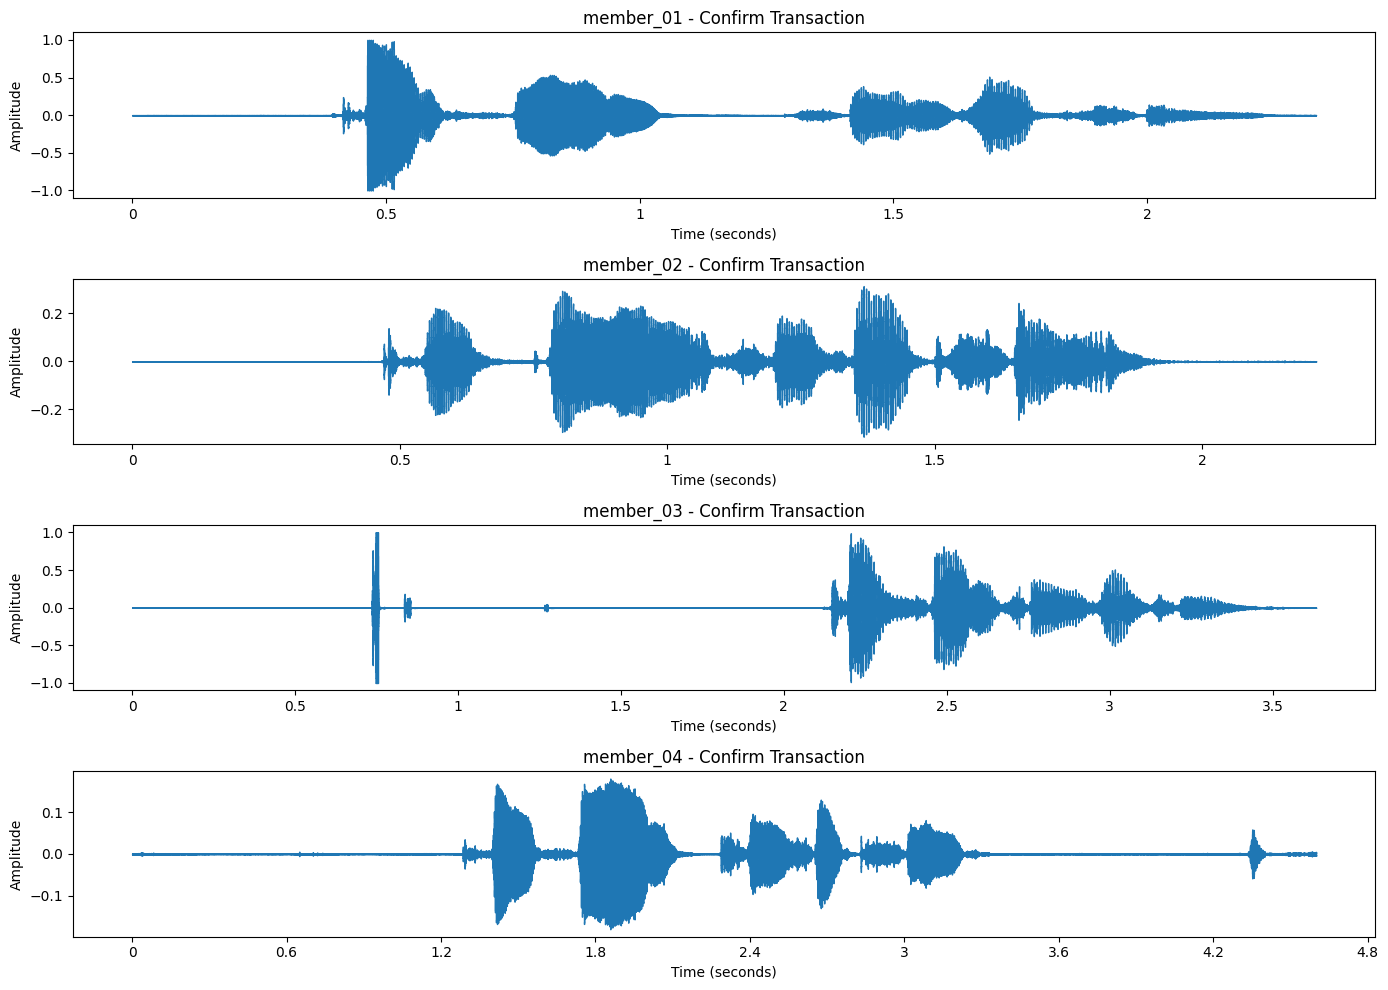

In [10]:
import matplotlib.pyplot as plt
import librosa
import librosa.display
import os

plt.figure(figsize=(14, 10))

for i, member in enumerate(sorted(os.listdir(DATASET_PATH))):
    member_path = os.path.join(DATASET_PATH, member)

    if not os.path.isdir(member_path):
        continue

    file_path = os.path.join(
        member_path,
        "confirm_transaction.wav"
    )

    audio, sample_rate = librosa.load(
        file_path,
        sr=None,
        mono=True
    )

    plt.subplot(4, 1, i + 1)

    librosa.display.waveshow(
        audio,
        sr=sample_rate
    )

    plt.title(f"{member} - Confirm Transaction")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

### Step 4.1: Waveform and Mel Spectrogram Visualization

We visualize both original recordings from each participant: `confirm_transaction.wav` and `yes_approve.wav`.

For each recording, we display:
- The waveform, showing amplitude variations over time.
- The Mel spectrogram, showing how the distribution of audio frequencies changes over time.

The Mel spectrogram is calculated from the audio signal and converted to decibels for visualization. These visualizations help us inspect the recordings before augmentation and feature extraction.

Total original recordings: 8


,member,recording,sample_rate,duration_seconds,channels
0,member_01,confirm_transaction.wav,48000,2.33,1
1,member_01,yes_approve.wav,48000,2.19,1
2,member_02,confirm_transaction.wav,48000,2.21,1
3,member_02,yes_approve.wav,48000,2.01,1
4,member_03,confirm_transaction.wav,48000,3.63,1
5,member_03,yes_approve.wav,48000,2.07,1
6,member_04,confirm_transaction.wav,48000,4.60,1
7,member_04,yes_approve.wav,48000,4.10,1


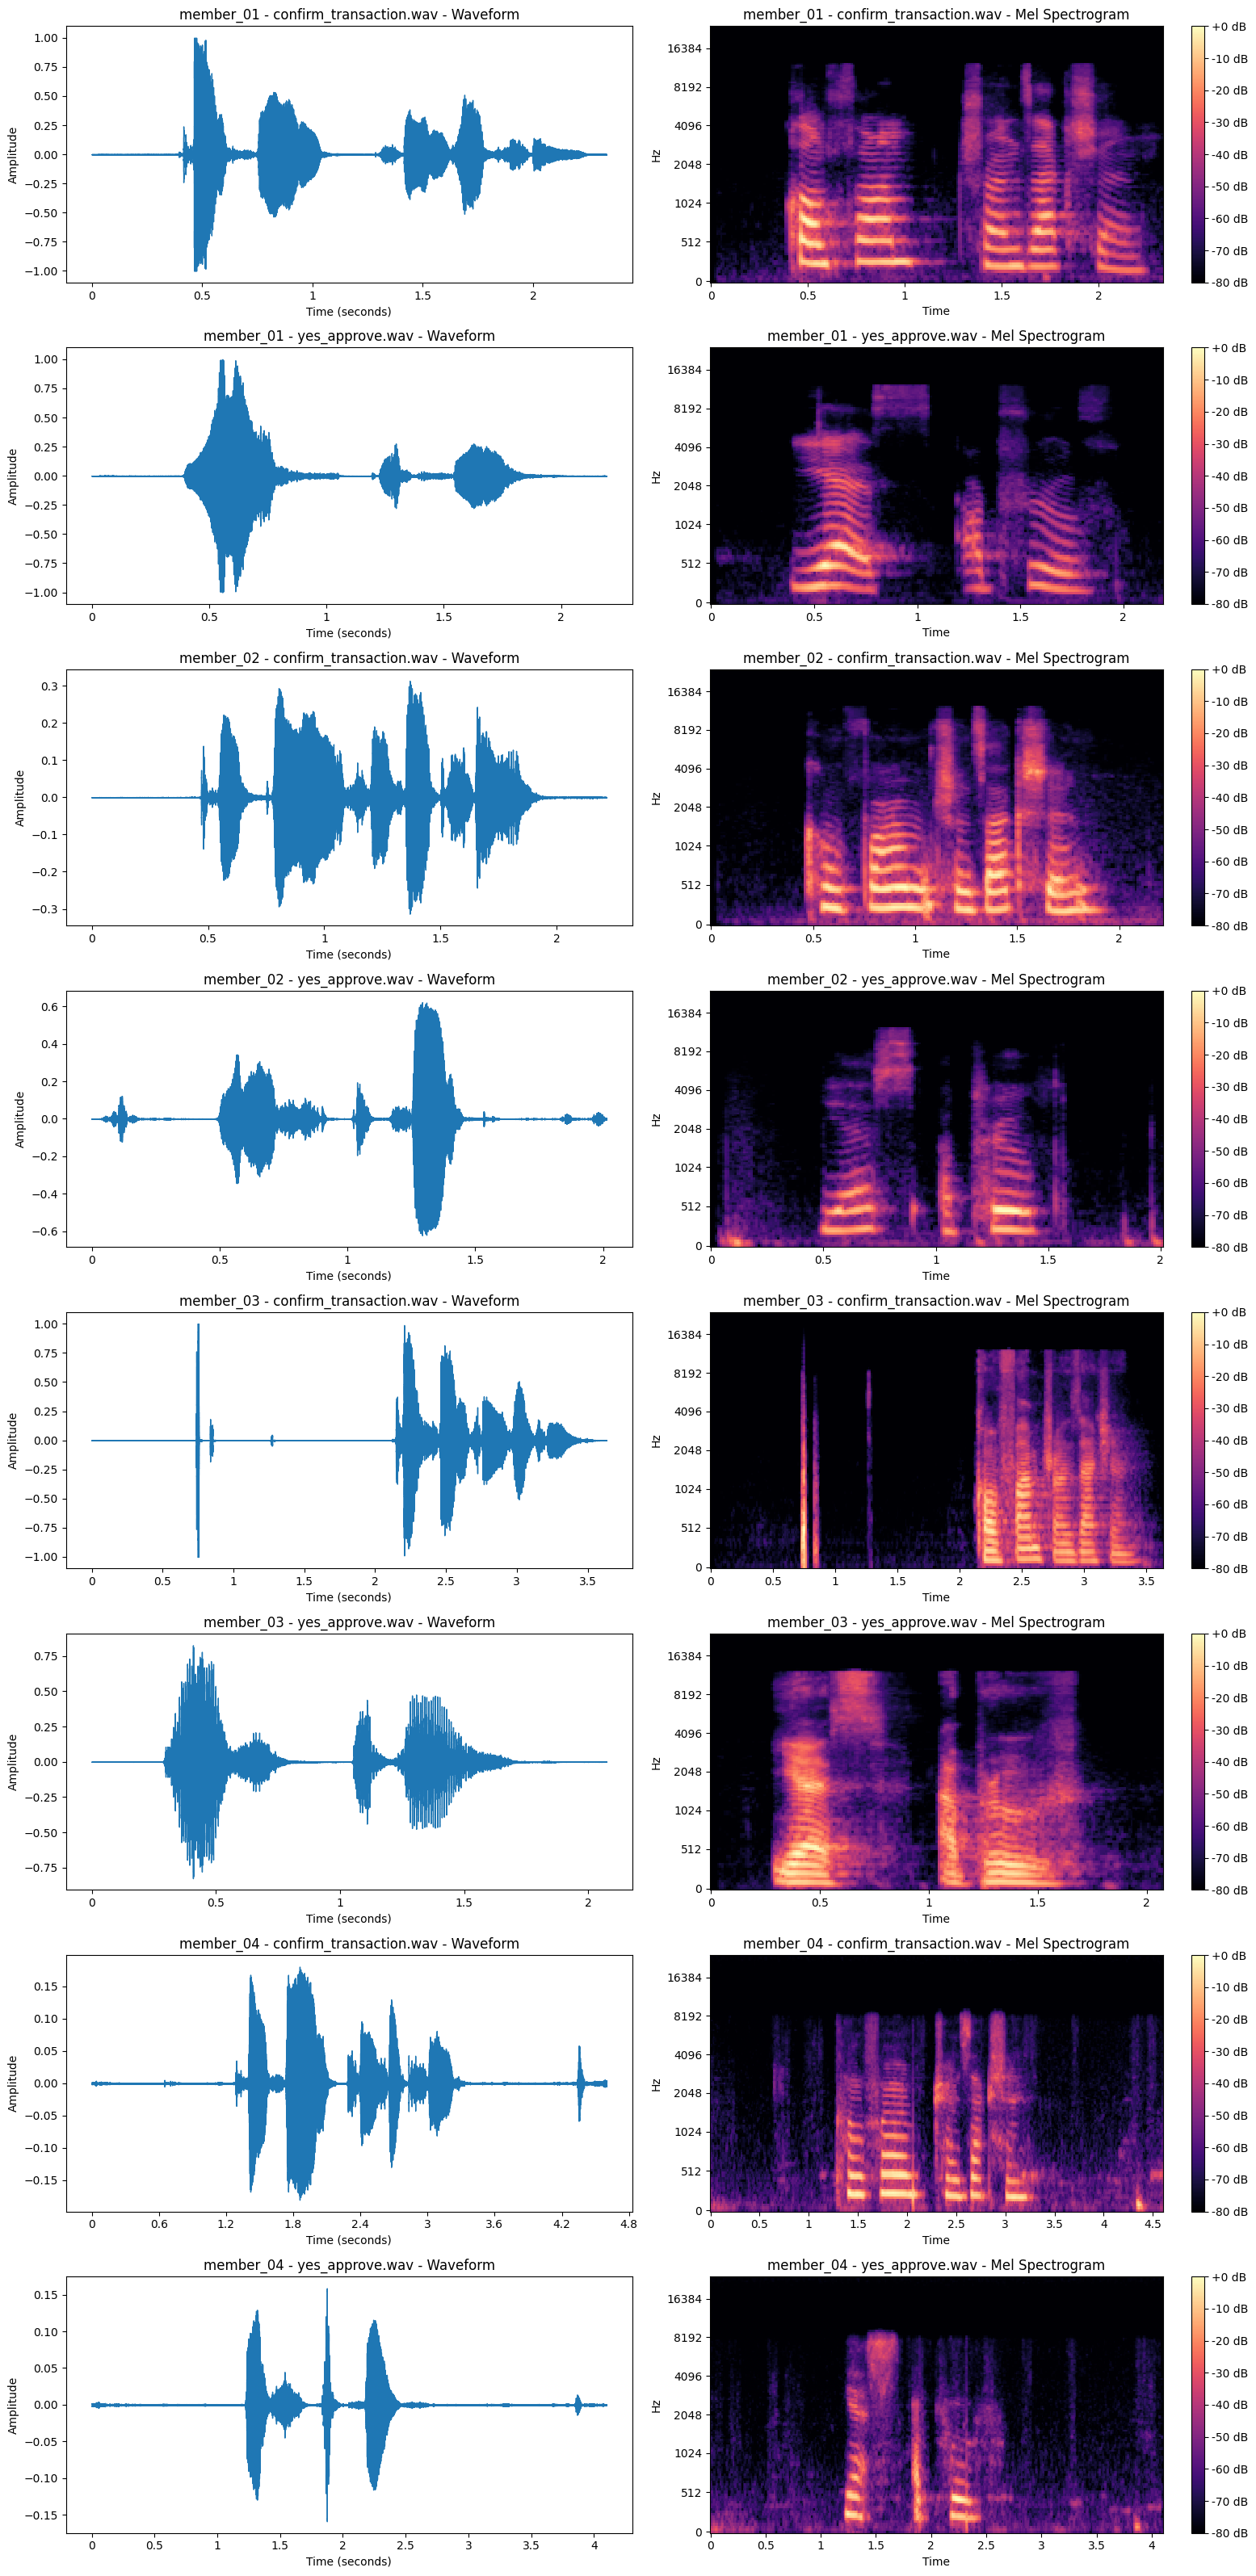

In [47]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

# Collect all eight original recordings
audio_files = sorted(Path(DATASET_PATH).glob("member_*/*.wav"))

print("Total original recordings:", len(audio_files))

# Display loading information
audio_information = []

for file_path in audio_files:
    audio, sr = librosa.load(
        str(file_path),
        sr=None,
        mono=True
    )

    audio_information.append({
        "member": file_path.parent.name,
        "recording": file_path.name,
        "sample_rate": sr,
        "duration_seconds": round(len(audio) / sr, 2),
        "channels": 1
    })

display(pd.DataFrame(audio_information))

# Plot waveform and Mel spectrogram for every recording
fig, axes = plt.subplots(
    nrows=len(audio_files),
    ncols=2,
    figsize=(16, 4 * len(audio_files))
)

for i, file_path in enumerate(audio_files):

    audio, sr = librosa.load(
        str(file_path),
        sr=None,
        mono=True
    )

    # Waveform
    librosa.display.waveshow(
        audio,
        sr=sr,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(
        f"{file_path.parent.name} - {file_path.name} - Waveform"
    )
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")

    # Mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_mels=128
    )

    mel_spec_db = librosa.power_to_db(
        mel_spec,
        ref=np.max
    )

    image = librosa.display.specshow(
        mel_spec_db,
        sr=sr,
        x_axis="time",
        y_axis="mel",
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(
        f"{file_path.parent.name} - {file_path.name} - Mel Spectrogram"
    )

    fig.colorbar(
        image,
        ax=axes[i, 1],
        format="%+2.0f dB"
    )

plt.tight_layout()
plt.show()

## Step 5: Training and Testing Data Preparation

Before applying data augmentation, we divide the original recordings into training and testing groups.

Training data:
- confirm_transaction.wav from all four participants.

Testing data:
- yes_approve.wav from all four participants.

This separation ensures that augmented versions of training recordings cannot leak into the test dataset.

The testing dataset will contain only original recordings. Since the dataset is small, the evaluation results will be exploratory rather than evidence of reliable real-world speaker verification.

In [11]:
import os
import pandas as pd

training_records = []
testing_records = []

for member in sorted(os.listdir(DATASET_PATH)):
    member_path = os.path.join(DATASET_PATH, member)

    if not os.path.isdir(member_path):
        continue

    for filename in sorted(os.listdir(member_path)):

        record = {
            "member_id": member,
            "filename": filename,
            "file_path": os.path.join(member_path, filename)
        }

        if filename == "confirm_transaction.wav":
            training_records.append(record)

        elif filename == "yes_approve.wav":
            testing_records.append(record)

train_df = pd.DataFrame(training_records)
test_df = pd.DataFrame(testing_records)

print("Training recordings:", len(train_df))
print("Testing recordings:", len(test_df))

print("\nTraining dataset:")
display(train_df)

print("\nTesting dataset:")
display(test_df)

Training recordings: 4
Testing recordings: 4

Training dataset:


,member_id,filename,file_path
0,member_01,confirm_transaction.wav,/content/data/audio/member_01/confirm_transact...
1,member_02,confirm_transaction.wav,/content/data/audio/member_02/confirm_transact...
2,member_03,confirm_transaction.wav,/content/data/audio/member_03/confirm_transact...
3,member_04,confirm_transaction.wav,/content/data/audio/member_04/confirm_transact...



Testing dataset:


,member_id,filename,file_path
0,member_01,yes_approve.wav,/content/data/audio/member_01/yes_approve.wav
1,member_02,yes_approve.wav,/content/data/audio/member_02/yes_approve.wav
2,member_03,yes_approve.wav,/content/data/audio/member_03/yes_approve.wav
3,member_04,yes_approve.wav,/content/data/audio/member_04/yes_approve.wav


## Step 6: Audio Data Augmentation

Audio data augmentation creates modified versions of existing recordings to introduce controlled variation into the training dataset.

We apply two techniques:

1. Pitch Shifting: Changes the pitch of the audio by two semitones.
2. Time Stretching: Changes the playback speed slightly using a rate of 1.1 without changing the pitch.

Both techniques are applied consistently to all four training recordings.

The original test recordings are not augmented. This prevents augmented versions of test recordings from entering the training dataset.

Augmentation increases the number of training examples but does not increase the number of independent speakers or original recordings.

In [12]:
import librosa
import os
import pandas as pd

augmented_records = []

for _, row in train_df.iterrows():

    audio, sample_rate = librosa.load(
        row["file_path"],
        sr=None,
        mono=True
    )

    # Keep the original training recording
    augmented_records.append({
        "member_id": row["member_id"],
        "filename": row["filename"],
        "source_recording": row["filename"],
        "recording_type": "original",
        "audio": audio,
        "sample_rate": sample_rate
    })

    # Pitch shifting: increase pitch by two semitones
    pitch_audio = librosa.effects.pitch_shift(
        y=audio,
        sr=sample_rate,
        n_steps=2
    )

    augmented_records.append({
        "member_id": row["member_id"],
        "filename": row["filename"],
        "source_recording": row["filename"],
        "recording_type": "pitch_shift",
        "audio": pitch_audio,
        "sample_rate": sample_rate
    })

    # Time stretching: slightly slow down the audio
    stretch_audio = librosa.effects.time_stretch(
        y=audio,
        rate=1.1
    )

    augmented_records.append({
        "member_id": row["member_id"],
        "filename": row["filename"],
        "source_recording": row["filename"],
        "recording_type": "time_stretch",
        "audio": stretch_audio,
        "sample_rate": sample_rate
    })

print("Audio augmentation completed!")
print("Total training samples:", len(augmented_records))

augmentation_summary = pd.DataFrame([
    {
        "member_id": record["member_id"],
        "source_recording": record["source_recording"],
        "recording_type": record["recording_type"],
        "duration_seconds": round(
            len(record["audio"]) / record["sample_rate"], 2
        )
    }
    for record in augmented_records
])

display(augmentation_summary)

Audio augmentation completed!
Total training samples: 12


,member_id,source_recording,recording_type,duration_seconds
0,member_01,confirm_transaction.wav,original,2.33
1,member_01,confirm_transaction.wav,pitch_shift,2.33
2,member_01,confirm_transaction.wav,time_stretch,2.12
3,member_02,confirm_transaction.wav,original,2.21
4,member_02,confirm_transaction.wav,pitch_shift,2.21
5,member_02,confirm_transaction.wav,time_stretch,2.01
6,member_03,confirm_transaction.wav,original,3.63
7,member_03,confirm_transaction.wav,pitch_shift,3.63
8,member_03,confirm_transaction.wav,time_stretch,3.30
9,member_04,confirm_transaction.wav,original,4.60


In [48]:
print("Variable type:", type(augmented_records))
print("Number of augmented records:", len(augmented_records))
print("First record:", augmented_records[0].keys())
print("Recording types:", sorted(set(
    record["recording_type"] for record in augmented_records
)))

Variable type: <class 'list'>
Number of augmented records: 12
First record: dict_keys(['member_id', 'filename', 'source_recording', 'recording_type', 'audio', 'sample_rate'])
Recording types: ['original', 'pitch_shift', 'time_stretch']


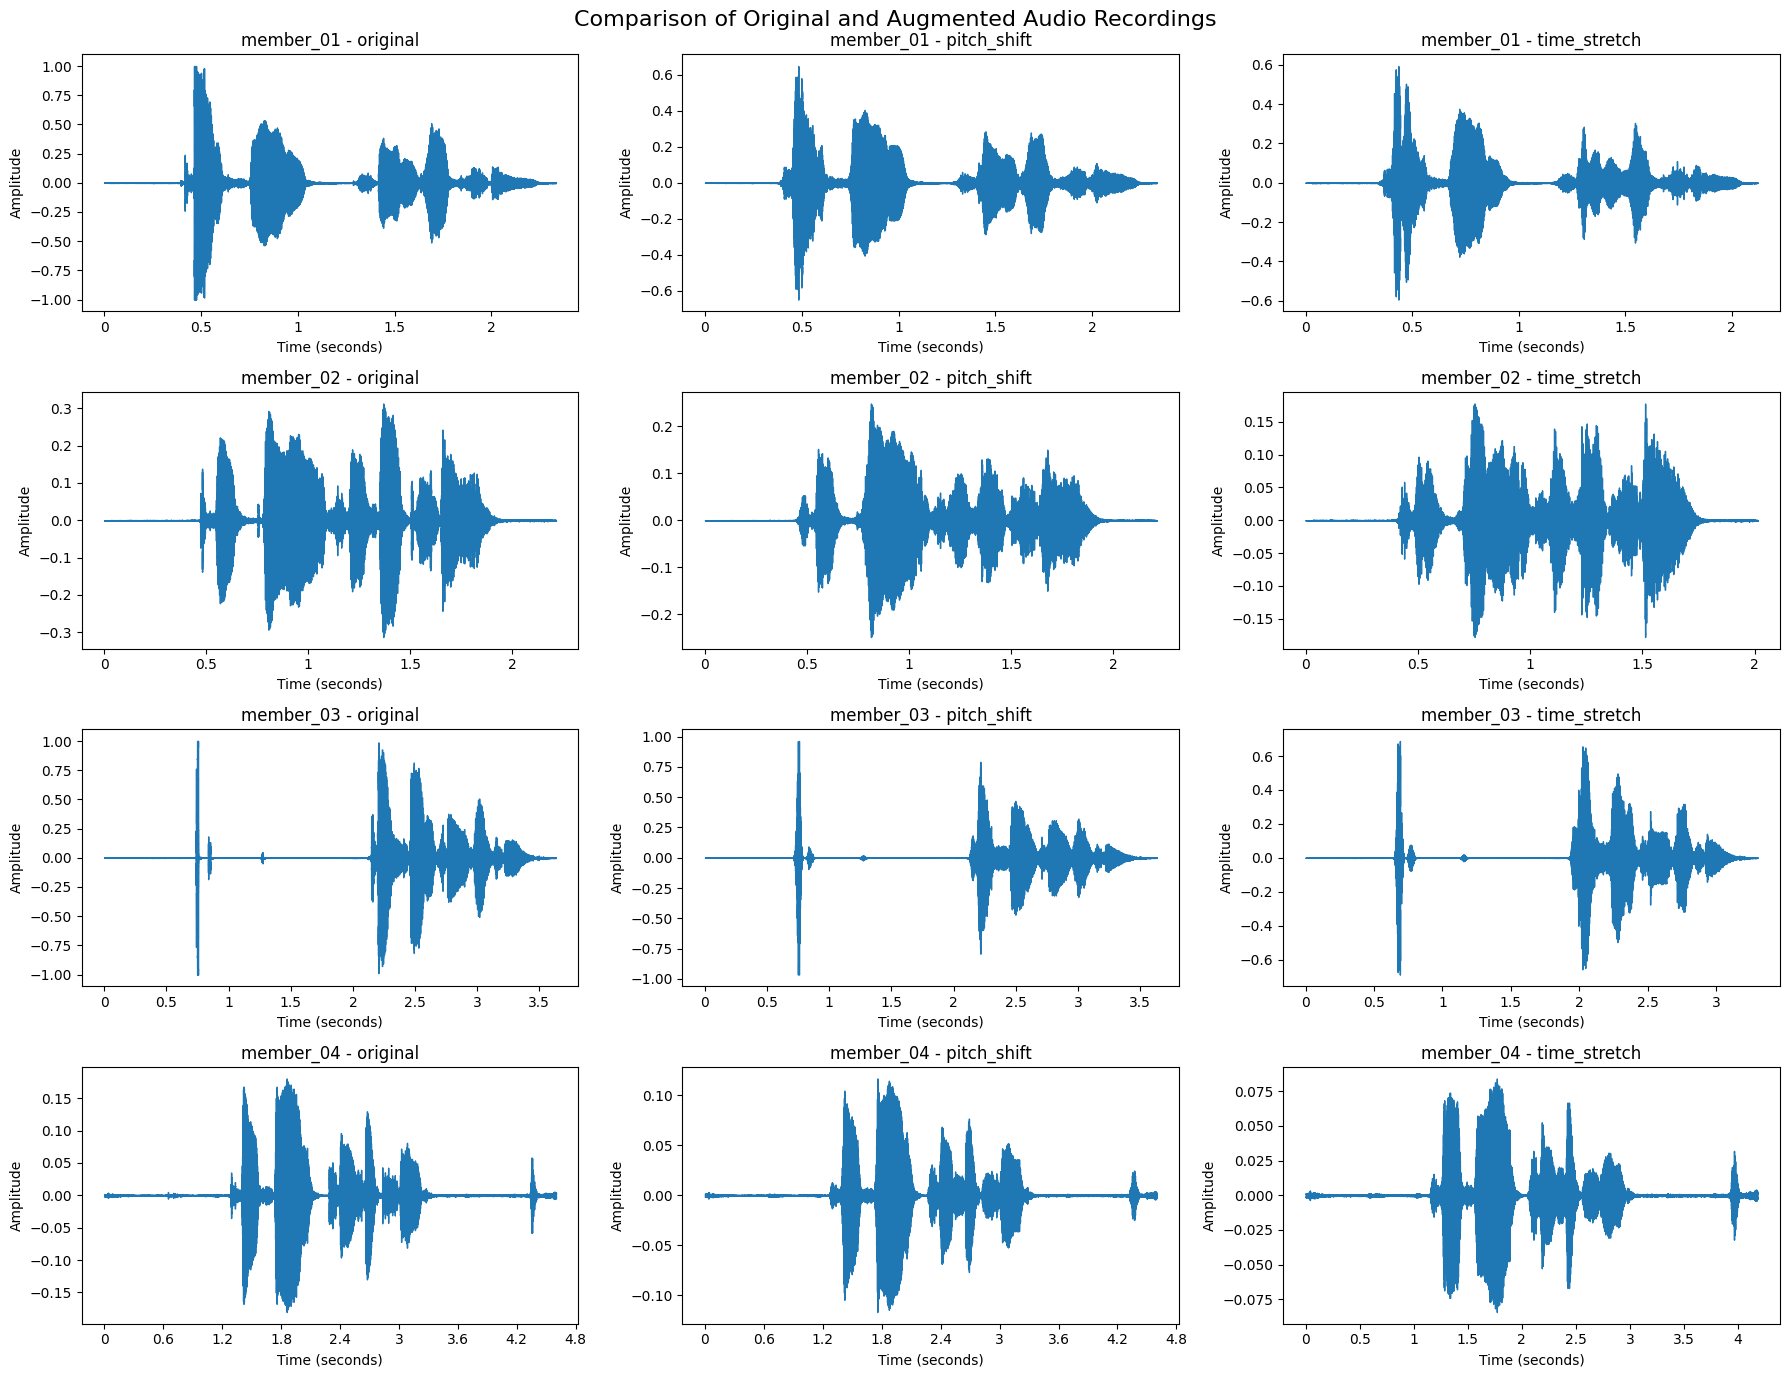

In [49]:
import matplotlib.pyplot as plt
import librosa.display

# The three recording types
recording_types = ["original", "pitch_shift", "time_stretch"]

# Four members × three recording types
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(18, 14)
)

members = sorted(set(
    record["member_id"] for record in augmented_records
))

for row, member in enumerate(members):

    for col, recording_type in enumerate(recording_types):

        # Find the matching recording
        record = next(
            item for item in augmented_records
            if item["member_id"] == member
            and item["recording_type"] == recording_type
        )

        audio = record["audio"]
        sr = record["sample_rate"]

        # Display waveform
        librosa.display.waveshow(
            audio,
            sr=sr,
            ax=axes[row, col]
        )

        axes[row, col].set_title(
            f"{member} - {recording_type}"
        )

        axes[row, col].set_xlabel("Time (seconds)")
        axes[row, col].set_ylabel("Amplitude")

plt.suptitle(
    "Comparison of Original and Augmented Audio Recordings",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [63]:
import os

print("===== DATA FILES =====")
for root, dirs, files in os.walk("data"):
    for file in files:
        print(os.path.join(root, file))

print("\n===== MODEL FILES =====")
for root, dirs, files in os.walk("models"):
    for file in files:
        print(os.path.join(root, file))

print("\n===== NOTEBOOK OUTPUT VARIABLES =====")
for name in [
    "audio_features_df",
    "train_features_df",
    "test_features_df",
    "comparison_results",
    "results_df",
    "saved_model_results"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {getattr(obj, 'shape', type(obj).__name__)}")
    else:
        print(f"{name}: Not found")

===== DATA FILES =====
data/audio_features.csv
data/audio/member_02/confirm_transaction.wav
data/audio/member_02/yes_approve.wav
data/audio/member_04/confirm_transaction.wav
data/audio/member_04/yes_approve.wav
data/audio/member_01/confirm_transaction.wav
data/audio/member_01/yes_approve.wav
data/audio/member_03/confirm_transaction.wav
data/audio/member_03/yes_approve.wav

===== MODEL FILES =====
models/voice_feature_columns.pkl
models/voice_model.pkl

===== NOTEBOOK OUTPUT VARIABLES =====
audio_features_df: (16, 19)
train_features_df: (12, 19)
test_features_df: (4, 19)
comparison_results: (3, 5)
results_df: (4, 3)
saved_model_results: (4, 2)


## Step 7: Audio Feature Extraction

Raw audio signals cannot be directly used as input to our traditional machine-learning classifier. We therefore extract numerical representations of the recordings.

We use three audio feature extraction techniques:

- Mel-Frequency Cepstral Coefficients (MFCC): 13 coefficients representing important spectral characteristics.
- Spectral Rolloff: Represents the distribution of spectral energy.
- Root Mean Square (RMS) Energy: Represents the average energy of the audio signal.

For each recording, we calculate the mean of the extracted features over time.

This produces 15 numerical features per recording:

13 MFCC features + 1 spectral rolloff feature + 1 RMS energy feature.

The same feature extraction process will be applied to training and testing recordings.

In [13]:
import numpy as np
import librosa
import pandas as pd

def extract_audio_features(audio, sample_rate):

    # Extract 13 MFCC coefficients
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sample_rate,
        n_mfcc=13
    )

    # Extract spectral rolloff
    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=sample_rate
    )

    # Extract RMS energy
    rms_energy = librosa.feature.rms(
        y=audio
    )

    # Calculate mean values
    features = {}

    for i in range(13):
        features[f"mfcc_{i+1}"] = np.mean(mfcc[i])

    features["spectral_rolloff"] = np.mean(spectral_rolloff)
    features["rms_energy"] = np.mean(rms_energy)

    return features


print("Feature extraction function created successfully!")
print("Number of features:", 15)

Feature extraction function created successfully!
Number of features: 15


### Step 7.1: Extract Features from Training and Testing Recordings

We apply the same feature extraction function to both datasets.

The training dataset contains:
- Four original recordings.
- Four pitch-shifted recordings.
- Four time-stretched recordings.

The testing dataset contains four original recordings only.

For traceability, we preserve the participant ID, recording type, and source recording filename in the resulting feature tables.

In [14]:
# Extract features from training recordings
training_features = []

for record in augmented_records:
    features = extract_audio_features(
        record["audio"],
        record["sample_rate"]
    )

    features["member_id"] = record["member_id"]
    features["filename"] = record["filename"]
    features["source_recording"] = record["source_recording"]
    features["recording_type"] = record["recording_type"]

    training_features.append(features)

train_features_df = pd.DataFrame(training_features)


# Extract features from original testing recordings
testing_features = []

for _, row in test_df.iterrows():
    audio, sample_rate = librosa.load(
        row["file_path"],
        sr=None,
        mono=True
    )

    features = extract_audio_features(audio, sample_rate)

    features["member_id"] = row["member_id"]
    features["filename"] = row["filename"]
    features["source_recording"] = row["filename"]
    features["recording_type"] = "original"

    testing_features.append(features)

test_features_df = pd.DataFrame(testing_features)


print("Training feature dataset shape:", train_features_df.shape)
print("Testing feature dataset shape:", test_features_df.shape)

print("\nTraining recording types:")
print(train_features_df["recording_type"].value_counts())

print("\nTraining dataset preview:")
display(train_features_df.head())

print("\nTesting dataset preview:")
display(test_features_df.head())

Training feature dataset shape: (12, 19)
Testing feature dataset shape: (4, 19)

Training recording types:
recording_type
original        4
pitch_shift     4
time_stretch    4
Name: count, dtype: int64

Training dataset preview:


,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13,spectral_rolloff,rms_energy,member_id,filename,source_recording,recording_type
0,-381.767975,111.689552,-2.141192,19.970909,2.497330,-17.155243,-17.478867,-1.032350,5.921103,-12.240618,-4.414403,4.475717,-1.982670,6412.992295,0.067659,member_01,confirm_transaction.wav,confirm_transaction.wav,original
1,-414.655029,108.906036,-6.339072,19.511404,-7.448339,-21.382099,-14.352611,6.144122,0.263581,-14.198978,2.234698,0.439955,-7.305205,5231.913527,0.050580,member_01,confirm_transaction.wav,confirm_transaction.wav,pitch_shift
2,-421.478912,115.229202,-4.834681,20.616898,0.552568,-18.126364,-18.506178,-1.017082,7.140327,-12.609982,-4.093406,4.313676,-2.489141,6440.248116,0.040235,member_01,confirm_transaction.wav,confirm_transaction.wav,time_stretch
3,-481.271423,130.818756,18.546690,25.645826,-0.815518,-3.435987,-0.873970,-5.482518,-1.486206,-11.567010,-3.230752,2.480522,-5.485768,7941.481370,0.035805,member_02,confirm_transaction.wav,confirm_transaction.wav,original
4,-508.372833,127.460373,15.327231,20.699741,-9.639040,-4.659677,-3.617930,-4.851938,-5.485466,-11.329057,2.532167,-1.500719,-4.976404,6894.794171,0.025262,member_02,confirm_transaction.wav,confirm_transaction.wav,pitch_shift



Testing dataset preview:


,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13,spectral_rolloff,rms_energy,member_id,filename,source_recording,recording_type
0,-387.177246,76.816948,15.535187,12.243598,-8.360073,-2.751550,-7.619548,-9.376917,-8.432226,-11.156900,4.807004,-0.990721,-5.116383,8652.988471,0.062680,member_01,yes_approve.wav,yes_approve.wav,original
1,-436.316193,84.535744,27.670111,30.999874,10.145111,1.176542,3.837404,0.694300,-3.697788,-5.709923,2.104497,2.806817,-0.519553,6210.813492,0.043976,member_02,yes_approve.wav,yes_approve.wav,original
2,-401.525574,112.610825,8.512689,19.153030,-9.123200,21.584871,0.807252,-2.369058,1.684711,-19.336164,1.785599,-4.219256,-1.197506,8640.985577,0.057218,member_03,yes_approve.wav,yes_approve.wav,original
3,-604.945190,83.159042,15.314004,21.562571,12.793823,4.512437,8.421024,-2.978189,2.270783,3.327470,-4.739154,-2.146393,-1.993906,14476.461039,0.005143,member_04,yes_approve.wav,yes_approve.wav,original


## Step 8: Feature Dataset Quality Checks

Before training the machine-learning model, we validate the extracted feature datasets.

We check:

1. Missing values.
2. Infinite numerical values.
3. Duplicate rows.
4. Participant distribution.
5. Recording-type distribution.

These checks help ensure that the feature datasets are suitable for model training and evaluation.

In [15]:
import numpy as np

# Select numerical feature columns
feature_columns = [
    f"mfcc_{i}" for i in range(1, 14)
] + ["spectral_rolloff", "rms_energy"]

# Check missing values
print("TRAINING DATA")
print("Missing values:", train_features_df[feature_columns].isnull().sum().sum())

print("\nTESTING DATA")
print("Missing values:", test_features_df[feature_columns].isnull().sum().sum())

# Check infinite values
print("\nInfinite values in training:",
      np.isinf(train_features_df[feature_columns].to_numpy()).sum())

print("Infinite values in testing:",
      np.isinf(test_features_df[feature_columns].to_numpy()).sum())

# Check duplicate feature rows
print("\nDuplicate training rows:",
      train_features_df.duplicated(subset=feature_columns).sum())

print("Duplicate testing rows:",
      test_features_df.duplicated(subset=feature_columns).sum())

# Participant distribution
print("\nTraining participant distribution:")
print(train_features_df["member_id"].value_counts().sort_index())

print("\nTesting participant distribution:")
print(test_features_df["member_id"].value_counts().sort_index())

TRAINING DATA
Missing values: 0

TESTING DATA
Missing values: 0

Infinite values in training: 0
Infinite values in testing: 0

Duplicate training rows: 0
Duplicate testing rows: 0

Training participant distribution:
member_id
member_01    3
member_02    3
member_03    3
member_04    3
Name: count, dtype: int64

Testing participant distribution:
member_id
member_01    1
member_02    1
member_03    1
member_04    1
Name: count, dtype: int64


## Step 9: Preparing Features and Target Labels

Machine-learning models require input features (X) and target labels (y).

We separate the 15 extracted audio features from the participant identifiers.

The input features represent the acoustic characteristics of each recording, while the target labels identify the participant who produced the recording.

We preserve the original participant names as string labels throughout training and evaluation.

The metadata columns are excluded from model inputs to prevent the model from learning directly from filenames or recording descriptions.

In [16]:
# Prepare training features and labels
X_train = train_features_df[feature_columns]
y_train = train_features_df["member_id"]

# Prepare testing features and labels
X_test = test_features_df[feature_columns]
y_test = test_features_df["member_id"]

print("Training features shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("\nTesting features shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

print("\nTraining classes:", sorted(y_train.unique()))
print("Testing classes:", sorted(y_test.unique()))

print("\nFeature columns:")
print(feature_columns)

Training features shape: (12, 15)
Training labels shape: (12,)

Testing features shape: (4, 15)
Testing labels shape: (4,)

Training classes: ['member_01', 'member_02', 'member_03', 'member_04']
Testing classes: ['member_01', 'member_02', 'member_03', 'member_04']

Feature columns:
['mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 'mfcc_6', 'mfcc_7', 'mfcc_8', 'mfcc_9', 'mfcc_10', 'mfcc_11', 'mfcc_12', 'mfcc_13', 'spectral_rolloff', 'rms_energy']


## Step 10: Training the Random Forest Classification Model

We use a Random Forest classifier to recognize participants based on their extracted audio features.

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Model configuration:
- Number of trees: 100
- Random state: 42
- Class weighting: Balanced

The model is trained using the augmented training dataset containing 12 samples.

The four original testing recordings remain completely separate from training.

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
voice_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
voice_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

print("\nNumber of training samples:", len(X_train))
print("Number of input features:", X_train.shape[1])
print("Number of classes:", len(voice_model.classes_))

print("\nModel classes:")
print(voice_model.classes_)

Random Forest model trained successfully!

Number of training samples: 12
Number of input features: 15
Number of classes: 4

Model classes:
['member_01' 'member_02' 'member_03' 'member_04']


## Step 11: Model Evaluation

We evaluate the trained Random Forest classifier using the four original recordings reserved for testing.

We use the following evaluation metrics:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Because the testing dataset contains only four recordings, each participant contributes just one test example.

The evaluation is exploratory and should not be interpreted as proof of reliable real-world speaker recognition.

MODEL EVALUATION RESULTS
------------------------
Accuracy: 0.5
Precision: 0.375
Recall: 0.5
F1 Score: 0.4167

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   member_01       0.00      0.00      0.00         1
   member_02       0.50      1.00      0.67         1
   member_03       0.00      0.00      0.00         1
   member_04       1.00      1.00      1.00         1

    accuracy                           0.50         4
   macro avg       0.38      0.50      0.42         4
weighted avg       0.38      0.50      0.42         4



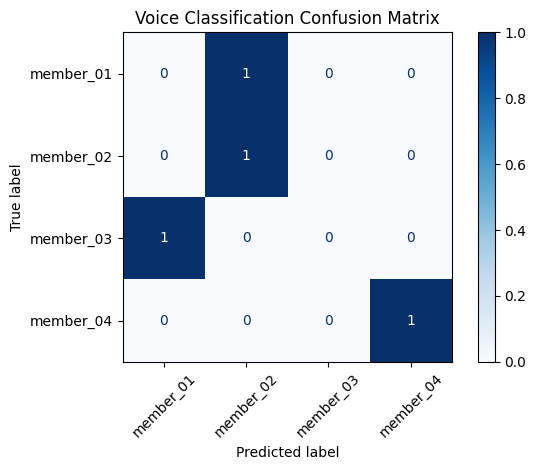


ACTUAL VS PREDICTED


,Actual,Predicted,Correct
0,member_01,member_02,False
1,member_02,member_02,True
2,member_03,member_01,False
3,member_04,member_04,True


In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display as show_table
import matplotlib.pyplot as plt
import pandas as pd

# Generate predictions
y_pred = voice_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=voice_model.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=voice_model.classes_)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=voice_model.classes_
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Voice Classification Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Actual versus predicted
results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Correct": y_test.values == y_pred
})

print("\nACTUAL VS PREDICTED")
show_table(results_df)

## Step 12: Experiment 2 — Support Vector Machine

In this experiment, we train a Support Vector Machine (SVM) classifier.

SVM identifies decision boundaries that separate different participant classes using their extracted audio features.

Since audio features have different numerical ranges, we apply StandardScaler before classification.

We use a pipeline to ensure that feature scaling is fitted only on the training data, preventing information leakage from the test dataset.

We evaluate SVM using the same four original test recordings used for Random Forest.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced"
    ))
])

# Train SVM
svm_model.fit(X_train, y_train)

# Predict test labels
svm_predictions = svm_model.predict(X_test)

# Evaluate SVM
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(
    y_test, svm_predictions,
    average="macro",
    zero_division=0
)
svm_recall = recall_score(
    y_test, svm_predictions,
    average="macro",
    zero_division=0
)
svm_f1 = f1_score(
    y_test, svm_predictions,
    average="macro",
    zero_division=0
)

print("SVM EVALUATION RESULTS")
print("----------------------")
print("Accuracy:", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall:", round(svm_recall, 4))
print("F1 Score:", round(svm_f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    svm_predictions,
    labels=sorted(y_train.unique()),
    zero_division=0
))

SVM EVALUATION RESULTS
----------------------
Accuracy: 0.75
Precision: 0.625
Recall: 0.75
F1 Score: 0.6667

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   member_01       0.00      0.00      0.00         1
   member_02       0.50      1.00      0.67         1
   member_03       1.00      1.00      1.00         1
   member_04       1.00      1.00      1.00         1

    accuracy                           0.75         4
   macro avg       0.62      0.75      0.67         4
weighted avg       0.62      0.75      0.67         4



## Step 13: Experiment 3 — K-Nearest Neighbors

In this experiment, we train a K-Nearest Neighbors (KNN) classifier.

KNN classifies a recording by comparing its extracted audio features with the nearest examples in the training dataset.

We use three nearest neighbors (k=3) and StandardScaler to normalize the numerical features.

The model uses Euclidean distance to measure similarity between feature vectors.

We evaluate KNN using the same four original test recordings to maintain consistency across experiments.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create KNN pipeline
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=3,
        metric="euclidean"
    ))
])

# Train KNN
knn_model.fit(X_train, y_train)

# Generate predictions
knn_predictions = knn_model.predict(X_test)

# Evaluate KNN
knn_accuracy = accuracy_score(y_test, knn_predictions)

knn_precision = precision_score(
    y_test, knn_predictions,
    average="macro",
    zero_division=0
)

knn_recall = recall_score(
    y_test, knn_predictions,
    average="macro",
    zero_division=0
)

knn_f1 = f1_score(
    y_test, knn_predictions,
    average="macro",
    zero_division=0
)

print("KNN EVALUATION RESULTS")
print("----------------------")
print("Accuracy:", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1 Score:", round(knn_f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    knn_predictions,
    labels=sorted(y_train.unique()),
    zero_division=0
))

KNN EVALUATION RESULTS
----------------------
Accuracy: 0.75
Precision: 0.625
Recall: 0.75
F1 Score: 0.6667

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   member_01       0.00      0.00      0.00         1
   member_02       1.00      1.00      1.00         1
   member_03       0.50      1.00      0.67         1
   member_04       1.00      1.00      1.00         1

    accuracy                           0.75         4
   macro avg       0.62      0.75      0.67         4
weighted avg       0.62      0.75      0.67         4



In [64]:
print("===== MODEL COMPARISON =====")
display(comparison_results)

print("\n===== TEST PREDICTIONS =====")
display(results_df)

print("\n===== SAVED MODEL RESULTS =====")
display(saved_model_results)

print("\n===== AUDIO FEATURE DATASET =====")
display(audio_features_df.head())

print("\n===== FEATURE DATASET QUALITY =====")
print("Shape:", audio_features_df.shape)
print("Missing values:", audio_features_df.isnull().sum().sum())
print("Duplicate rows:", audio_features_df.duplicated().sum())

===== MODEL COMPARISON =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.50,0.375,0.50,0.416667
1,SVM,0.75,0.625,0.75,0.666667
2,KNN,0.75,0.625,0.75,0.666667



===== TEST PREDICTIONS =====


,Actual,Predicted,Correct
0,member_01,member_02,False
1,member_02,member_02,True
2,member_03,member_01,False
3,member_04,member_04,True



===== SAVED MODEL RESULTS =====


,Actual Member,Predicted Member
0,member_01,member_02
1,member_02,member_02
2,member_03,member_03
3,member_04,member_04



===== AUDIO FEATURE DATASET =====


,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13,spectral_rolloff,rms_energy,member_id,filename,source_recording,recording_type
0,-381.767975,111.689552,-2.141192,19.970909,2.497330,-17.155243,-17.478867,-1.032350,5.921103,-12.240618,-4.414403,4.475717,-1.982670,6412.992295,0.067659,member_01,confirm_transaction.wav,confirm_transaction.wav,original
1,-414.655029,108.906036,-6.339072,19.511404,-7.448339,-21.382099,-14.352611,6.144122,0.263581,-14.198978,2.234698,0.439955,-7.305205,5231.913527,0.050580,member_01,confirm_transaction.wav,confirm_transaction.wav,pitch_shift
2,-421.478912,115.229202,-4.834681,20.616898,0.552568,-18.126364,-18.506178,-1.017082,7.140327,-12.609982,-4.093406,4.313676,-2.489141,6440.248116,0.040235,member_01,confirm_transaction.wav,confirm_transaction.wav,time_stretch
3,-481.271423,130.818756,18.546690,25.645826,-0.815518,-3.435987,-0.873970,-5.482518,-1.486206,-11.567010,-3.230752,2.480522,-5.485768,7941.481370,0.035805,member_02,confirm_transaction.wav,confirm_transaction.wav,original
4,-508.372833,127.460373,15.327231,20.699741,-9.639040,-4.659677,-3.617930,-4.851938,-5.485466,-11.329057,2.532167,-1.500719,-4.976404,6894.794171,0.025262,member_02,confirm_transaction.wav,confirm_transaction.wav,pitch_shift



===== FEATURE DATASET QUALITY =====
Shape: (16, 19)
Missing values: 0
Duplicate rows: 0


,member_id,recording_type,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,spectral_rolloff,rms_energy
0,member_01,original,-381.76797,111.68955,-2.141192,19.970910,2.497330,6412.992295,0.067659
1,member_01,pitch_shift,-414.65503,108.90604,-6.339072,19.511404,-7.448339,5231.913527,0.050580
2,member_01,time_stretch,-421.47890,115.22920,-4.834681,20.616898,0.552568,6440.248116,0.040235
3,member_02,original,-481.27142,130.81876,18.546690,25.645826,-0.815518,7941.481370,0.035805
4,member_02,pitch_shift,-508.37283,127.46037,15.327231,20.699741,-9.639040,6894.794171,0.025262
5,member_02,time_stretch,-518.24210,136.45010,15.998601,27.014473,-2.934526,7735.863095,0.022481
6,member_03,original,-421.45685,81.54309,2.928646,11.950092,-1.274396,12821.687133,0.046721
7,member_03,pitch_shift,-450.77220,81.37384,0.133992,10.220813,-2.528433,9944.029509,0.034483
8,member_03,time_stretch,-445.88870,81.55563,1.990797,11.190005,-1.957410,12269.531250,0.033584
9,member_04,original,-564.27020,106.90372,8.372270,22.224460,17.104305,11192.545573,0.011854


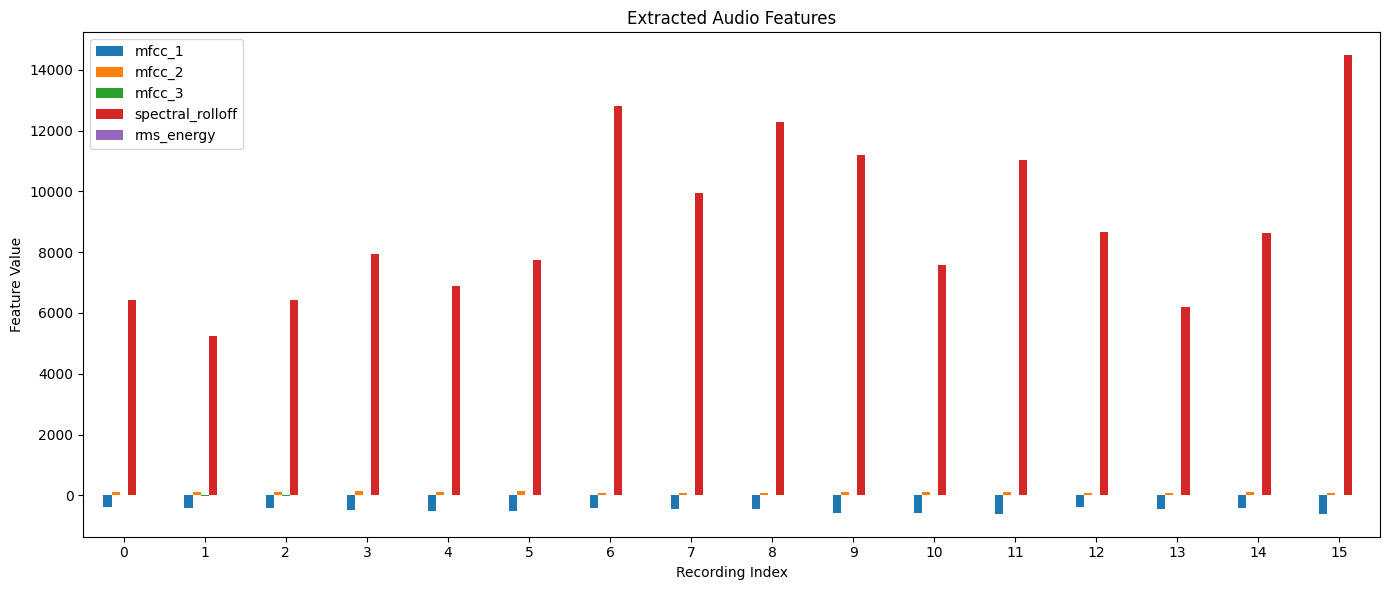

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Load the extracted audio features
df = pd.read_csv("data/audio_features.csv")

# Display the important feature columns
feature_columns = [
    "member_id",
    "recording_type",
    "mfcc_1",
    "mfcc_2",
    "mfcc_3",
    "mfcc_4",
    "mfcc_5",
    "spectral_rolloff",
    "rms_energy"
]

display(df[feature_columns].head(10))

# Create a visual comparison of the extracted features
plot_columns = [
    "mfcc_1",
    "mfcc_2",
    "mfcc_3",
    "spectral_rolloff",
    "rms_energy"
]

df[plot_columns].plot(
    kind="bar",
    figsize=(14, 6),
    title="Extracted Audio Features"
)

plt.xlabel("Recording Index")
plt.ylabel("Feature Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 14: Model Performance Comparison

We compare the three trained classification algorithms:

1. Random Forest
2. Support Vector Machine (SVM)
3. K-Nearest Neighbors (KNN)

We compare their accuracy, macro precision, macro recall, and macro F1-score.

Using the same training and testing datasets ensures that the experiments are directly comparable.

The results are exploratory because the testing dataset contains only four original recordings.

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.50,0.375,0.50,0.4167
1,SVM,0.75,0.625,0.75,0.6667
2,KNN,0.75,0.625,0.75,0.6667


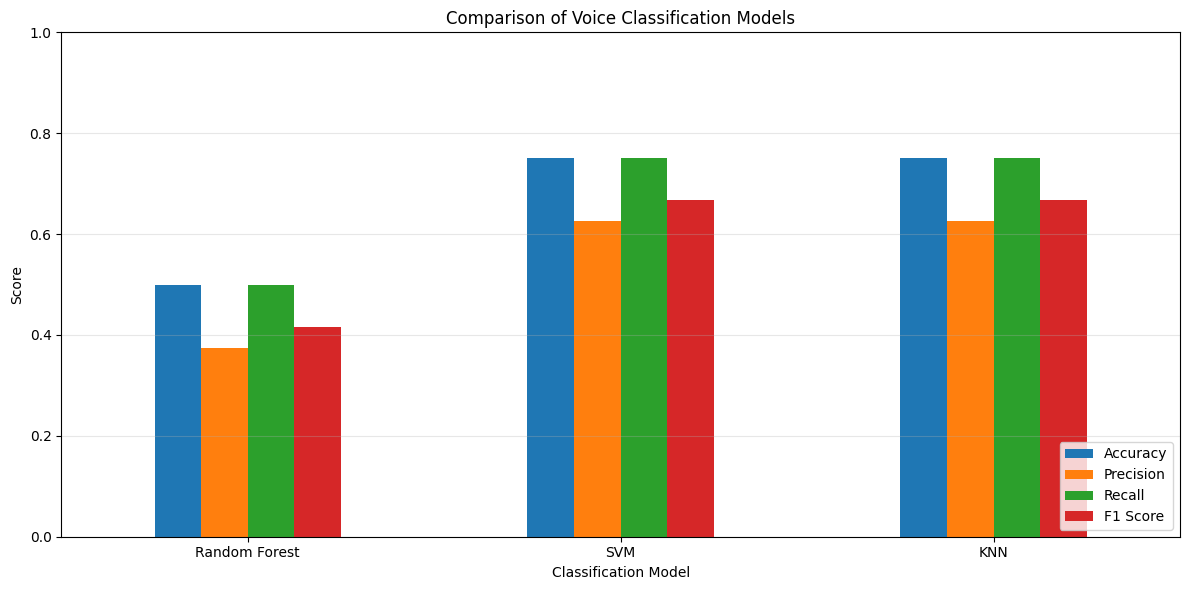

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Collect model evaluation results
comparison_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "KNN"],
    "Accuracy": [accuracy, svm_accuracy, knn_accuracy],
    "Precision": [precision, svm_precision, knn_precision],
    "Recall": [recall, svm_recall, knn_recall],
    "F1 Score": [f1, svm_f1, knn_f1]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison_results.round(4))

# Visualize performance metrics
comparison_results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparison of Voice Classification Models")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 15: Individual Model Prediction Analysis

This step compares the predictions made by Random Forest, SVM, and KNN for each test recording.

We will identify which participants are correctly classified and investigate any consistent misclassifications.

In [26]:
prediction_comparison = pd.DataFrame({
    "Actual Member": y_test.values,
    "Random Forest": y_pred,
    "SVM": svm_predictions,
    "KNN": knn_predictions
})

prediction_comparison["RF Correct"] = (
    prediction_comparison["Actual Member"] ==
    prediction_comparison["Random Forest"]
)

prediction_comparison["SVM Correct"] = (
    prediction_comparison["Actual Member"] ==
    prediction_comparison["SVM"]
)

prediction_comparison["KNN Correct"] = (
    prediction_comparison["Actual Member"] ==
    prediction_comparison["KNN"]
)

print("INDIVIDUAL PREDICTION COMPARISON")
show_table(prediction_comparison)

INDIVIDUAL PREDICTION COMPARISON


,Actual Member,Random Forest,SVM,KNN,RF Correct,SVM Correct,KNN Correct
0,member_01,member_02,member_02,member_03,False,False,False
1,member_02,member_02,member_02,member_02,True,True,True
2,member_03,member_01,member_03,member_03,False,True,True
3,member_04,member_04,member_04,member_04,True,True,True


### Step 16: Investigating Misclassified Audio Features

We investigate the misclassification of member_01 by measuring the distance between its test audio features and the training audio features of each participant.

We use standardization because MFCC, spectral rolloff, and RMS energy have different numerical scales.

A smaller average distance indicates greater feature similarity. This is a diagnostic experiment, not proof of speaker identity.

In [27]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Standardize training and testing features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Select member_01's test recording
member01_index = y_test[y_test == "member_01"].index[0]
member01_position = y_test.index.get_loc(member01_index)

member01_audio = X_test_scaled[member01_position]

# Calculate average distance to each participant's training recordings
distance_results = []

for member in sorted(y_train.unique()):
    member_positions = np.where(y_train.values == member)[0]

    member_training_audio = X_train_scaled[member_positions]

    distances = np.linalg.norm(
        member_training_audio - member01_audio,
        axis=1
    )

    distance_results.append({
        "Participant": member,
        "Average Distance": distances.mean(),
        "Minimum Distance": distances.min()
    })

distance_df = pd.DataFrame(distance_results)

distance_df = distance_df.sort_values(
    by="Average Distance"
).reset_index(drop=True)

print("FEATURE DISTANCE ANALYSIS FOR MEMBER_01")
show_table(distance_df.round(4))

FEATURE DISTANCE ANALYSIS FOR MEMBER_01


,Participant,Average Distance,Minimum Distance
0,member_02,5.5932,4.5768
1,member_03,5.6148,5.4505
2,member_01,6.9901,6.2828
3,member_04,7.7307,7.4094


### Step 17: Save the Selected Model

SVM was selected for the final voice verification integration because it achieved the highest observed test accuracy, tied with K-Nearest Neighbors (KNN).

The evaluation results were:

- Random Forest: 50% accuracy.
- Support Vector Machine (SVM): 75% accuracy.
- K-Nearest Neighbors (KNN): 75% accuracy.

Although SVM and KNN achieved identical evaluation metrics, SVM was selected for integration into the final Python package.

We save:

- The trained SVM model.
- The list and order of numerical features expected by the model.

These files will be used in the voice verification integration package.

In [44]:
# Step 17: Save the Selected SVM Model

import os
import joblib

# Create the models directory
os.makedirs("models", exist_ok=True)

# Save the trained SVM model
joblib.dump(svm_model, "models/voice_model.pkl")

# Save the feature column names
joblib.dump(feature_columns, "models/voice_feature_columns.pkl")

print("SVM model saved successfully!")
print("Feature columns saved successfully!")

SVM model saved successfully!
Feature columns saved successfully!


In [67]:
print("===== FEATURE COLUMN NAMES =====")
print(loaded_feature_columns)

print("\nTotal feature columns:", len(loaded_feature_columns))

print("\n===== SAVED SVM EVALUATION =====")
print("Accuracy:", saved_accuracy)

print("\n===== SAVED MODEL PREDICTIONS =====")
print(saved_model_results.to_string(index=False))

===== FEATURE COLUMN NAMES =====
['mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 'mfcc_6', 'mfcc_7', 'mfcc_8', 'mfcc_9', 'mfcc_10', 'mfcc_11', 'mfcc_12', 'mfcc_13', 'spectral_rolloff', 'rms_energy']

Total feature columns: 15

===== SAVED SVM EVALUATION =====
Accuracy: 0.75

===== SAVED MODEL PREDICTIONS =====
Actual Member Predicted Member
    member_01        member_02
    member_02        member_02
    member_03        member_03
    member_04        member_04


In [66]:
print("===== SAVED FEATURE COLUMNS =====")

print("Available feature variables:")

for name in globals():
    if "feature" in name.lower() and "column" in name.lower():
        print(name, ":", type(globals()[name]))

print("\n===== SAVED MODEL FEATURE COUNT =====")
print("Expected features:", loaded_voice_model.n_features_in_)

===== SAVED FEATURE COLUMNS =====
Available feature variables:
feature_columns : <class 'list'>
loaded_feature_columns : <class 'list'>

===== SAVED MODEL FEATURE COUNT =====
Expected features: 15


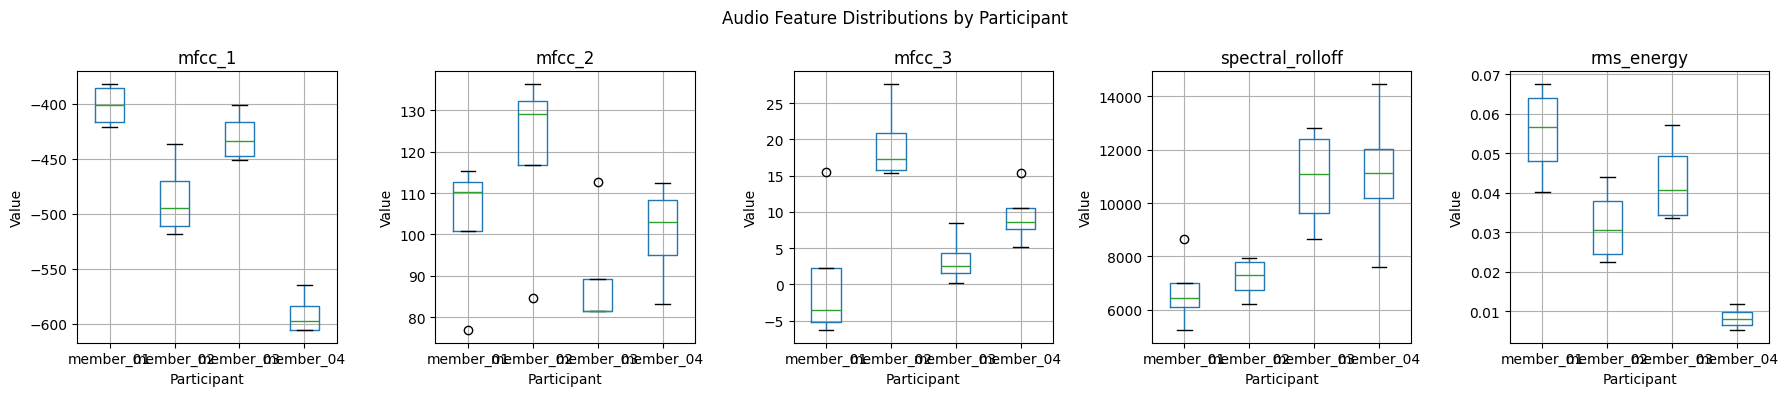

In [68]:
import matplotlib.pyplot as plt

features = [
    "mfcc_1",
    "mfcc_2",
    "mfcc_3",
    "spectral_rolloff",
    "rms_energy"
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, feature in zip(axes, features):
    audio_features_df.boxplot(
        column=feature,
        by="member_id",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Participant")
    ax.set_ylabel("Value")

plt.suptitle("Audio Feature Distributions by Participant")
plt.tight_layout()
plt.show()

In [69]:
print("===== AUDIO EVIDENCE CHECKLIST =====")

checks = {
    "Original waveform and Mel spectrogram": "audio_files",
    "Augmented recordings": "augmented_records",
    "Training features": "train_features_df",
    "Testing features": "test_features_df",
    "Combined audio features": "audio_features_df",
    "Model comparison": "comparison_results",
    "Saved SVM model": "loaded_voice_model",
    "Saved model predictions": "saved_model_results"
}

for description, variable in checks.items():
    print(
        f"{'PRESENT' if variable in globals() else 'MISSING'}: "
        f"{description}"
    )

===== AUDIO EVIDENCE CHECKLIST =====
PRESENT: Original waveform and Mel spectrogram
PRESENT: Augmented recordings
PRESENT: Training features
PRESENT: Testing features
PRESENT: Combined audio features
PRESENT: Model comparison
PRESENT: Saved SVM model
PRESENT: Saved model predictions


### Step 18: Verifying the Saved SVM Voice Model

We reload the saved SVM model and feature configuration from disk.

We then use the reloaded model to predict the test recordings. This confirms that the saved model can be loaded and used independently of the original training process.

The predictions are compared with the actual participant labels to check that the saved model retains its expected classification behavior.

In [45]:
# Step 18: Verify the Saved SVM Voice Model

import joblib
import pandas as pd
from sklearn.metrics import accuracy_score

# Load the saved SVM model and feature columns
loaded_voice_model = joblib.load("models/voice_model.pkl")

loaded_feature_columns = joblib.load(
    "models/voice_feature_columns.pkl"
)

# Prepare test features using the saved feature order
X_test_saved = X_test[loaded_feature_columns]

# Generate predictions
saved_model_predictions = loaded_voice_model.predict(
    X_test_saved
)

# Compare actual and predicted participants
saved_model_results = pd.DataFrame({
    "Actual Member": y_test.values,
    "Predicted Member": saved_model_predictions
})

# Calculate accuracy
saved_accuracy = accuracy_score(
    y_test,
    saved_model_predictions
)

# Display results
print("SAVED SVM MODEL VERIFICATION")
show_table(saved_model_results)

print("\nModel loaded successfully.")
print("Number of features:", len(loaded_feature_columns))
print(f"Saved SVM Model Accuracy: {saved_accuracy:.2%}")

SAVED SVM MODEL VERIFICATION


,Actual Member,Predicted Member
0,member_01,member_02
1,member_02,member_02
2,member_03,member_03
3,member_04,member_04



Model loaded successfully.
Number of features: 15
Saved SVM Model Accuracy: 75.00%


### Step 19: Creating the Voice Verification Package

The trained SVM model is integrated into a reusable Python package maintained in the project repository.

The package separates audio feature extraction from voice verification, making the functionality easier to import and reuse.

The package contains:

- `voice_verification/__init__.py`: Exposes the main verification function.
- `voice_verification/features.py`: Provides audio feature extraction.
- `voice_verification/verifier.py`: Loads the trained model and performs voice verification.

### Step 20: Audio Feature Extraction Module

The audio feature extraction module processes WAV recordings and extracts the same 15 numerical features used during model training:

- 13 MFCC mean coefficients.
- Mean spectral rolloff.
- Mean RMS energy.

The extraction process uses Librosa and preserves consistency between training and prediction.

The extracted features are arranged in the expected order before being passed to the trained SVM model.

### Step 21: Implementing the Voice Verification Function

The voice verification module connects the trained SVM model with the audio feature extraction module.

Its main responsibilities are:

- Loading the saved SVM model and feature columns.
- Accepting a WAV file path and an expected participant identifier.
- Extracting the required audio features.
- Predicting the participant using the trained model.
- Comparing the predicted participant with the expected participant.
- Returning a structured verification result.

The model artifacts are loaded and reused to avoid unnecessary repeated loading.

### Step 22: Initializing the Voice Verification Package

The package initializer exposes the `verify_voice` function.

This allows other project modules to import the verification functionality directly:

`from voice_verification import verify_voice`

The package provides a simple interface without requiring users to manage the internal feature extraction and model-loading operations.

### Step 23: Testing the Voice Verification Package

The reusable voice verification package was tested in the project environment.

The test confirmed that:

- The package imports successfully.
- The saved SVM model loads successfully.
- The feature extraction function is available.
- The voice verification function is available.

The verification function accepts an audio file path and an expected participant identifier.

### Step 24: Testing Package Compatibility

The package compatibility test confirmed that the voice verification components work together.

The test checked the model-loading function, feature extraction function, and main verification interface.

The package was successfully imported, and the trained SVM pipeline was loaded with all 15 expected features.

The notebook's independent test evaluation remains 75% accuracy. This should not be confused with a separate package integration test.

### Step 25: Inspecting the Voice Verification Package

The final package structure in the project repository is:

- `src/audio_utils.py`: Audio feature extraction, artifact loading, and voice verification logic.
- `src/train_voice_model.py`: Model training and artifact generation.
- `voice_verification/__init__.py`: Package initialization.
- `voice_verification/features.py`: Feature extraction interface.
- `voice_verification/verifier.py`: Voice verification interface.
- `models/voice_model.pkl`: Saved SVM model.
- `models/voice_feature_columns.pkl`: Expected feature columns.

The package import and model-loading checks were completed successfully in the project environment.

Step 28 — Prepare to transfer the new model

In [42]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

joblib.dump(svm_model, "models/voice_model.pkl")
joblib.dump(feature_columns, "models/voice_feature_columns.pkl")

print("SVM model saved successfully!")
print("Feature columns saved successfully!")

SVM model saved successfully!
Feature columns saved successfully!


,Actual Member,Predicted Member,Result
0,member_01,member_02,False
1,member_02,member_02,True
2,member_03,member_03,True
3,member_04,member_04,True


Saved SVM Model Accuracy: 75.00%
Correct predictions: 3 out of 4


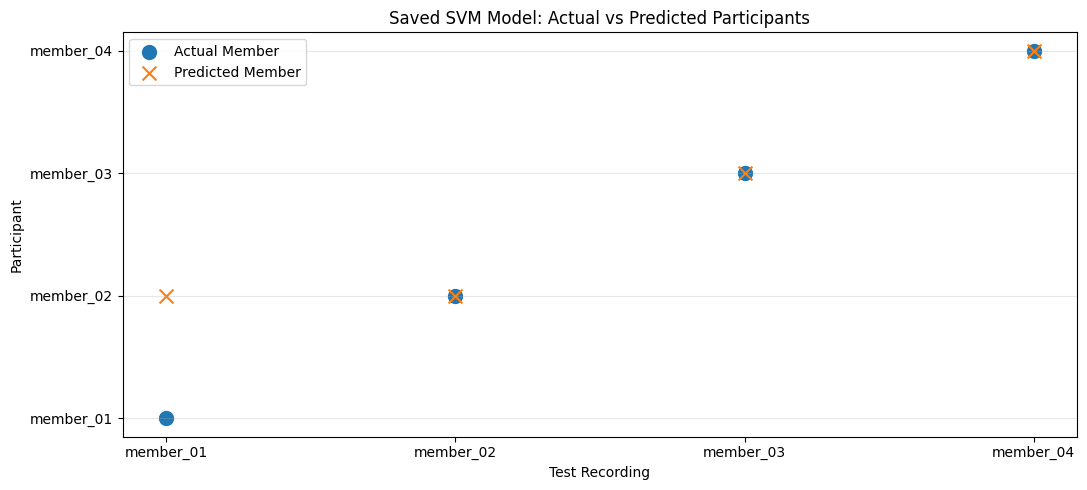

In [72]:
import pandas as pd
import matplotlib.pyplot as plt

# Saved SVM model predictions
saved_model_results = pd.DataFrame({
    "Actual Member": [
        "member_01",
        "member_02",
        "member_03",
        "member_04"
    ],
    "Predicted Member": [
        "member_02",
        "member_02",
        "member_03",
        "member_04"
    ]
})

# Check whether each prediction is correct
saved_model_results["Result"] = (
    saved_model_results["Actual Member"]
    == saved_model_results["Predicted Member"]
)

# Display prediction results
display(saved_model_results)

# Calculate accuracy
accuracy = saved_model_results["Result"].mean()

print(f"Saved SVM Model Accuracy: {accuracy:.2%}")
print(
    f"Correct predictions: "
    f"{saved_model_results['Result'].sum()} out of "
    f"{len(saved_model_results)}"
)

# Visualize actual vs predicted identities
x = range(len(saved_model_results))

plt.figure(figsize=(11, 5))

plt.scatter(
    x,
    saved_model_results["Actual Member"],
    label="Actual Member",
    marker="o",
    s=100
)

plt.scatter(
    x,
    saved_model_results["Predicted Member"],
    label="Predicted Member",
    marker="x",
    s=100
)

plt.xticks(
    list(x),
    saved_model_results["Actual Member"]
)

plt.xlabel("Test Recording")
plt.ylabel("Participant")
plt.title("Saved SVM Model: Actual vs Predicted Participants")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
from google.colab import files

files.download("models/voice_model.pkl")
files.download("models/voice_feature_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>